# Asymptote Fits for Graph Invariants

Load the precomputed invariant measurements across checkpoints and fit finite-size correction curves to estimate their limiting behavior.


In [1]:
import json
import pathlib

import matplotlib.pyplot as plt
import numpy as np
from refig import refig

from zfish.asymptote import (
    PROGRESS_LEVELS,
    PLOT_EXCLUDE,
    DEFAULT_MODEL_SPECS,
    average_milestones,
    build_summary_lines,
    chunked,
    compute_checkpoint_metadata,
    estimate_progress_edit,
    fit_invariants,
    get_limit_value,
    predict_from_fit,
)

plt.rcParams["svg.fonttype"] = "none"
plt.rcParams["font.family"] = "Roboto"
plt.rcParams["figure.dpi"] = 150

DATA_PATH = pathlib.Path("invariants_per_graph.json")
# if not DATA_PATH.exists():
#     DATA_PATH = pathlib.Path("../notebooks/invariants_per_graph.json")
if not DATA_PATH.exists():
    raise FileNotFoundError(
        "Could not locate invariants_per_graph.json relative to this notebook. Run the Connectome-Invariants notebook to generate it."
    )

FIGURE_DIR = pathlib.Path("figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)


/Users/mateljk1/Documents/projects/aplbrain/zebrafish-pencilsdown/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:

with open(DATA_PATH) as f:
    invariants_per_graph = json.load(f)

checkpoint_labels, checkpoint_edits, checkpoint_lookup, DEFAULT_SHIFT = compute_checkpoint_metadata(
    invariants_per_graph
)

print(
    f"Loaded {len(invariants_per_graph)} invariants across "
    f"{len(checkpoint_labels)} checkpoints."
)
print(f"Checkpoint shift (delta) for feature transforms: {DEFAULT_SHIFT:.0f} edits")


Loaded 11 invariants across 11 checkpoints.
Checkpoint shift (delta) for feature transforms: 2500 edits


In [3]:

MODEL_SPECS = DEFAULT_MODEL_SPECS

fit_results, skipped = fit_invariants(
    invariants_per_graph,
    checkpoint_labels,
    checkpoint_lookup,
    MODEL_SPECS,
    shift=DEFAULT_SHIFT,
)

print(f"Fitted asymptotes for {len(fit_results)} invariants.")
if skipped:
    print(
        "Skipped due to insufficient data or monotonic fits:",
        ", ".join(skipped),
    )


Fitted asymptotes for 11 invariants.


In [4]:

summary_lines = build_summary_lines(fit_results, progress_levels=PROGRESS_LEVELS, lang="latex")

print("Summary of fitted asymptotes:")
for line in summary_lines:
    print(line)

Summary of fitted asymptotes:
\begin{tabular}{l|l|r|rrrrr}
Invariant & Best model & Asymptote (L) & 50\% edits & 80\% edits & 90\% edits & 95\% edits & 99\% edits \\
\hline
average\_clustering & Exp-20k & 0.0216073 & \textit{13,832} & \textit{32,141} & \textit{46,023} & 60,030 & 92,296 \\
average\_degree & Poly-Linear & — & — & — & — & — & — \\
degree\_assortativity & Poly-Linear & — & — & — & — & — & — \\
degree\_entropy & Poly-Linear & — & — & — & — & — & — \\
density & Poly-Linear & — & — & — & — & — & — \\
diameter & Exp-20k & 5.87322 & \textit{15,558} & \textit{33,892} & \textit{47,749} & 61,781 & 93,797 \\
giant\_component\_fraction & Poly-Linear & — & — & — & — & — & — \\
molloy\_reed\_index & Exp-20k & 63.8416 & \textit{14,557} & \textit{32,866} & \textit{46,748} & 60,780 & 92,796 \\
reciprocity & Poly-Linear & — & — & — & — & — & — \\
transitivity & Exp-20k & 0.0235682 & \textit{14,282} & \textit{32,616} & \textit{46,473} & 60,530 & 92,546 \\
triangle\_count & Poly-Linear & — 

In [5]:
summary_lines

['\\begin{tabular}{l|l|r|rrrrr}',
 'Invariant & Best model & Asymptote (L) & 50\\% edits & 80\\% edits & 90\\% edits & 95\\% edits & 99\\% edits \\\\',
 '\\hline',
 'average\\_clustering & Exp-20k & 0.0216073 & \\textit{13,832} & \\textit{32,141} & \\textit{46,023} & 60,030 & 92,296 \\\\',
 'average\\_degree & Poly-Linear & — & — & — & — & — & — \\\\',
 'degree\\_assortativity & Poly-Linear & — & — & — & — & — & — \\\\',
 'degree\\_entropy & Poly-Linear & — & — & — & — & — & — \\\\',
 'density & Poly-Linear & — & — & — & — & — & — \\\\',
 'diameter & Exp-20k & 5.87322 & \\textit{15,558} & \\textit{33,892} & \\textit{47,749} & 61,781 & 93,797 \\\\',
 'giant\\_component\\_fraction & Poly-Linear & — & — & — & — & — & — \\\\',
 'molloy\\_reed\\_index & Exp-20k & 63.8416 & \\textit{14,557} & \\textit{32,866} & \\textit{46,748} & 60,780 & 92,796 \\\\',
 'reciprocity & Poly-Linear & — & — & — & — & — & — \\\\',
 'transitivity & Exp-20k & 0.0235682 & \\textit{14,282} & \\textit{32,616} & \\tex

/var/folders/1z/9cg7xdn56bl0jc6kbnbvddvh0000gn/T/ipykernel_51974/2365040972.py:72: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(
/var/folders/1z/9cg7xdn56bl0jc6kbnbvddvh0000gn/T/ipykernel_51974/2365040972.py:72: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(
/var/folders/1z/9cg7xdn56bl0jc6kbnbvddvh0000gn/T/ipykernel_51974/2365040972.py:72: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(
/var/folders/1z/9cg7xdn56bl0jc6kbnbvddvh0000gn/T/ipykernel_51974/2365040972.py:72: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(
/var/folders/1z/9cg7xdn56bl0jc6kbnbvddvh0000gn/T/ipykernel_51974/236

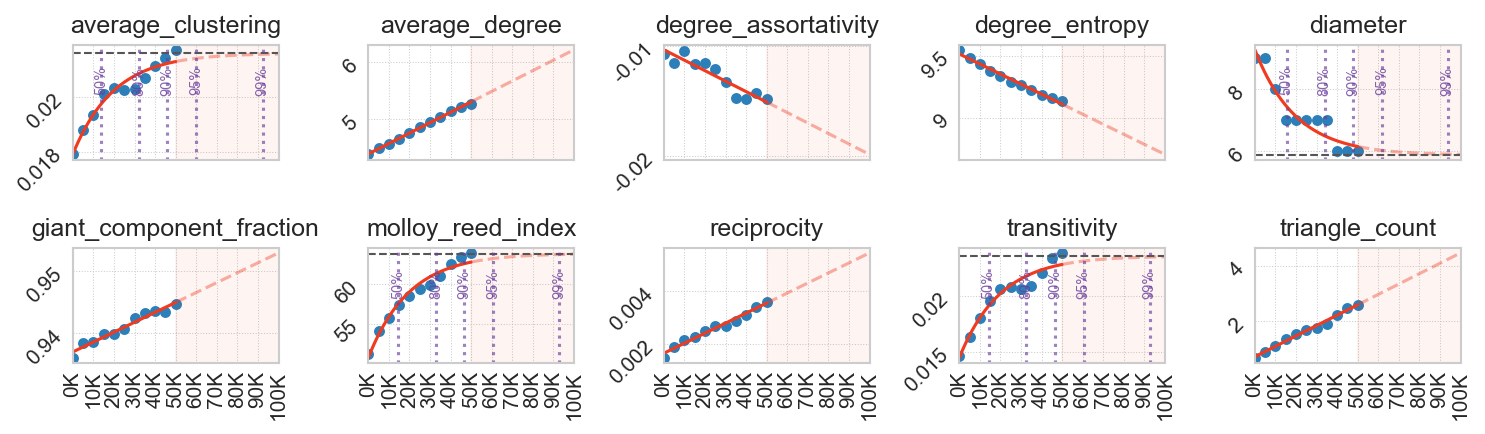

In [9]:

with plt.style.context("seaborn-v0_8-whitegrid"):
    sorted_results = sorted(fit_results, key=lambda item: item["invariant"])
    plot_results = [
        result
        for result in sorted_results
        if result["invariant"] not in PLOT_EXCLUDE
    ]
    group_size = 10
    future_limit = 100_000.0
    tick_min = 0
    tick_max = 100_000.0
    tick_inc = 10000.0
    xtick_positions = np.arange(tick_min, tick_max + 1e-9, tick_inc)
    xtick_labels = [f"{int(pos/1000)}K" for pos in xtick_positions]
    milestone_color = "#6a3d9a"
    for group_idx, group in enumerate(chunked(plot_results, group_size), start=1):
        fig, axes = plt.subplots(2, 5, figsize=(10, 3), sharex=True)
        axes = axes.flatten()
        for ax, result in zip(axes, group):
            x = result["x"]
            y = result["y"]
            best = result["best_fit"]
            limit_value = get_limit_value(best)
            last_observed = x.max()
            x_grid = np.linspace(x.min(), max(future_limit, last_observed), 600)
            y_grid = predict_from_fit(x_grid, best)

            ax.scatter(x, y, color="#2c7fb8", s=18)

            past_mask = x_grid <= last_observed
            ax.plot(
                x_grid[past_mask],
                y_grid[past_mask],
                color="#f03b20",
            )
            if np.any(~past_mask):
                ax.plot(
                    x_grid[~past_mask],
                    y_grid[~past_mask],
                    color="#f03b20",
                    alpha=0.4,
                    linestyle="--",
                )

            if limit_value is not None:
                ax.axhline(
                    limit_value,
                    color="#555555",
                    linestyle="--",
                    linewidth=1,
                )

            milestone_values = []
            for level in PROGRESS_LEVELS:
                edit_value = estimate_progress_edit(result, level, limit_value)
                if edit_value is None or edit_value > future_limit:
                    continue
                milestone_values.append((level, edit_value))

            if future_limit > last_observed:
                ax.axvspan(
                    last_observed,
                    future_limit,
                    color="#f03b20",
                    alpha=0.05,
                )

            ax.set_title(result["invariant"])
            ax.set_xlim(0, future_limit)
            ax.set_xticks(xtick_positions)
            ax.set_xticklabels(xtick_labels, rotation=90)
            ax.set_yticklabels(
                [f"{ytick:.2g}" for ytick in ax.get_yticks()],
                rotation=45,
            )

            ymin, ymax = ax.get_ylim()
            for level, edit_value in milestone_values:
                ax.axvline(
                    edit_value,
                    color=milestone_color,
                    linestyle=":",
                    linewidth=1.5,
                    alpha=0.65,
                )
                ax.annotate(
                    f"{int(level * 100)}%",
                    xy=(edit_value, ymax),
                    xytext=(0, -10),
                    textcoords="offset points",
                    rotation=90,
                    ha="center",
                    va="top",
                    fontsize=7,
                    color=milestone_color,
                    alpha=0.8,
                )

        for ax in axes:
            ax.grid(True, linestyle=":", linewidth=0.5)

        for ax in axes[len(group):]:
            ax.axis("off")

        fig.tight_layout(rect=(0, 0, 1, 1))

        output_path = FIGURE_DIR / f"asymptote-grid-{group_idx:02d}.svg"
        refig.savefig(str(output_path))
        plt.show()


In [7]:

average_milestones_mean, average_milestones_std, average_milestones_formatted = average_milestones(
    fit_results, progress_levels=PROGRESS_LEVELS
)
average_milestones_formatted


{0.5: '14,557 ± 633',
 0.8: '32,879 ± 640',
 0.9: '46,748 ± 633',
 0.95: '60,780 ± 638',
 0.99: '92,859 ± 570'}